In [20]:
# ========== 单元格 1：重读数据 ==========
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.formula.api as smf
import patsy
from statsmodels.stats.outliers_influence import variance_inflation_factor

path = r'C:\Users\13676\Desktop\senna_cohort.csv'
df = pd.read_csv(path, encoding='gb18030',
                 encoding_errors='replace', low_memory=False)

time_cols = ['index_time', 'baseline_k_charttime', 'hypokalemia_time',
             'window_event_time', 'admittime', 'dischtime', 'deathtime',
             'baseline_egfr_charttime']
for c in time_cols:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], dayfirst=True, errors='coerce')

df_main = df.dropna(subset=['senna_exposed', 'hypokalemia_event',
                             'baseline_k', 'age']).copy()
df_main['y'] = df_main['hypokalemia_event'].astype(int)
df_main['senna_exposed'] = df_main['senna_exposed'].astype(int)
df_main['gender_male'] = (df_main['gender'].str.upper().str[0] == 'M').astype(int)

# 确认新列进来了
print('新列存在:', 'drug_count_no_laxatives' in df_main.columns)
print('df_main 行数:', len(df_main))

# 对比新旧合并用药数
print('\n--- drug_count vs drug_count_no_laxatives 中位数 ---')
print(df_main.groupby('senna_exposed')[
    ['drug_count', 'drug_count_no_laxatives']
].median())

新列存在: True
df_main 行数: 41529

--- drug_count vs drug_count_no_laxatives 中位数 ---
               drug_count  drug_count_no_laxatives
senna_exposed                                     
0                 11.0000                  11.0000
1                 14.0000                  11.0000


In [21]:
# ========== 单元格 2：诊断 ==========
r, p = stats.pointbiserialr(
    df_main['senna_exposed'],
    pd.to_numeric(df_main['drug_count_no_laxatives'], errors='coerce')
)
print(f'点二列相关 r = {r:.3f}, P = {p:.3g}  (期望 < 0.15)')

models = {
    'M0 粗模型': 'senna_exposed',
    'M3 +人口学+K+合并症':
        'senna_exposed + gender_male + C(age_group, Treatment("65-74")) + baseline_k + chf + ckd + dm',
    'M4L +no_laxatives':
        'senna_exposed + gender_male + C(age_group, Treatment("65-74")) + baseline_k + chf + ckd + dm + drug_count_no_laxatives',
    'M5L +核心药物':
        'senna_exposed + gender_male + C(age_group, Treatment("65-74")) + baseline_k + chf + ckd + dm + drug_count_no_laxatives + diuretic + acei_arb + digoxin + insulin + statin + anticoagulant',
    'M6L +其他泻药':
        'senna_exposed + gender_male + C(age_group, Treatment("65-74")) + baseline_k + chf + ckd + dm + drug_count_no_laxatives + diuretic + acei_arb + digoxin + insulin + statin + anticoagulant + lactulose + peg + bisacodyl',
    'M7L +全部混杂':
        'senna_exposed + gender_male + C(age_group, Treatment("65-74")) + baseline_k + chf + ckd + dm + drug_count_no_laxatives + diuretic + acei_arb + digoxin + insulin + statin + anticoagulant + lactulose + peg + bisacodyl + ppi + beta2_agonist + corticosteroid',
}

results = []
for name, rhs in models.items():
    m = smf.logit(f'y ~ {rhs}', data=df_main).fit(disp=0)
    or_ = np.exp(m.params['senna_exposed'])
    lo = np.exp(m.conf_int().loc['senna_exposed', 0])
    hi = np.exp(m.conf_int().loc['senna_exposed', 1])
    p = m.pvalues['senna_exposed']
    results.append({'Model': name,
                    'senna aOR': round(or_, 3),
                    '95% CI': f'{lo:.3f}–{hi:.3f}',
                    'P': f'{p:.3g}'})
print('\n', pd.DataFrame(results).to_string(index=False))

点二列相关 r = 0.099, P = 2.56e-90  (期望 < 0.15)

             Model  senna aOR      95% CI        P
           M0 粗模型     1.2650 1.205–1.328 2.21e-21
    M3 +人口学+K+合并症     1.3410 1.276–1.410 3.89e-31
M4L +no_laxatives     1.1900 1.131–1.253 2.87e-11
        M5L +核心药物     1.1900 1.129–1.253 6.91e-11
        M6L +其他泻药     1.1760 1.111–1.245 2.44e-08
        M7L +全部混杂     1.1900 1.124–1.260 2.53e-09


In [22]:
# ========== 单元格 3：多因素主模型 ==========
def format_p(p):
    if pd.isna(p): return 'NA'
    if p < 1e-300: return '<1×10⁻³⁰⁰'
    if p >= 0.001: return f'{p:.3f}'
    e = int(np.floor(np.log10(p)))
    mant = p / (10 ** e)
    sup = str(e).translate(str.maketrans('-0123456789', '⁻⁰¹²³⁴⁵⁶⁷⁸⁹'))
    return f'{mant:.2f}×10{sup}'

def p_flag(p):
    return 'NA' if pd.isna(p) else ('Yes' if p < 0.05 else 'No')

main_formula = (
    'y ~ senna_exposed + gender_male + '
    'C(age_group, Treatment("65-74")) + '
    'baseline_k + drug_count_no_laxatives + '
    'chf + ckd + dm + '
    'diuretic + acei_arb + digoxin + insulin + statin + anticoagulant + '
    'lactulose + peg + bisacodyl + '
    'ppi + beta2_agonist + corticosteroid'
)

model_main = smf.logit(main_formula, data=df_main).fit(disp=0)

res = []
for term in model_main.params.index:
    if term == 'Intercept':
        continue
    p = model_main.pvalues[term]
    res.append({'Variable': term,
                'aOR': round(np.exp(model_main.params[term]), 3),
                '95% CI': f'{np.exp(model_main.conf_int().loc[term,0]):.3f}–'
                          f'{np.exp(model_main.conf_int().loc[term,1]):.3f}',
                'P': format_p(p),
                'P<0.05': p_flag(p)})
table3 = pd.DataFrame(res)
print('--- Table 3 多因素 Logistic 主模型 ---')
print(table3.to_string(index=False))
table3.to_excel('Table3_multivariable_logistic.xlsx', index=False)

# VIF
X = patsy.dmatrix(main_formula.split('~')[1], df_main, return_type='dataframe')
vif = pd.DataFrame({
    'Variable': X.columns,
    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
print('\n--- VIF (VIF>5 注意) ---')
print(vif.sort_values('VIF', ascending=False).to_string(index=False))

--- Table 3 多因素 Logistic 主模型 ---
                                 Variable    aOR      95% CI           P P<0.05
C(age_group, Treatment("65-74"))[T.75-84] 1.1150 1.053–1.181   2.13×10⁻⁴    Yes
  C(age_group, Treatment("65-74"))[T.85+] 1.2100 1.127–1.298   1.17×10⁻⁷    Yes
                            senna_exposed 1.1900 1.124–1.260   2.53×10⁻⁹    Yes
                              gender_male 0.7950 0.755–0.838  4.33×10⁻¹⁸    Yes
                               baseline_k 0.3240 0.304–0.345 5.07×10⁻²⁶⁴    Yes
                  drug_count_no_laxatives 1.1140 1.107–1.121 6.29×10⁻²⁵⁶    Yes
                                      chf 1.0730 1.007–1.144       0.031    Yes
                                      ckd 0.8390 0.786–0.895   8.95×10⁻⁸    Yes
                                       dm 0.7070 0.660–0.758  7.59×10⁻²³    Yes
                                 diuretic 1.2780 1.204–1.357  9.96×10⁻¹⁶    Yes
                                 acei_arb 0.6990 0.661–0.740  7.61×10⁻³⁶    Yes
       

In [23]:
# ========== 单元格 4：敏感性分析 ==========
def format_p(p):
    if pd.isna(p): return 'NA'
    if p < 1e-300: return '<1×10⁻³⁰⁰'
    if p >= 0.001: return f'{p:.3f}'
    e = int(np.floor(np.log10(p)))
    mant = p / (10 ** e)
    sup = str(e).translate(str.maketrans('-0123456789', '⁻⁰¹²³⁴⁵⁶⁷⁸⁹'))
    return f'{mant:.2f}×10{sup}'

# 敏感性 1：加入 docusate
formula_s1 = main_formula.replace(
    'lactulose + peg + bisacodyl',
    'lactulose + peg + bisacodyl + docusate'
)
m_s1 = smf.logit(formula_s1, data=df_main).fit(disp=0)
print('--- 敏感性 1：+ docusate ---')
print(f'  senna aOR = {np.exp(m_s1.params["senna_exposed"]):.3f} '
      f'({np.exp(m_s1.conf_int().loc["senna_exposed",0]):.3f}–'
      f'{np.exp(m_s1.conf_int().loc["senna_exposed",1]):.3f}), '
      f'P = {format_p(m_s1.pvalues["senna_exposed"])}')

# 敏感性 2：加入 potassium_supplement（反向因果）
m_s2 = smf.logit(main_formula + ' + potassium_supplement',
                 data=df_main).fit(disp=0)
print('\n--- 敏感性 2：+ potassium_supplement（反向因果）---')
print(f'  senna aOR = {np.exp(m_s2.params["senna_exposed"]):.3f} '
      f'({np.exp(m_s2.conf_int().loc["senna_exposed",0]):.3f}–'
      f'{np.exp(m_s2.conf_int().loc["senna_exposed",1]):.3f}), '
      f'P = {format_p(m_s2.pvalues["senna_exposed"])}')

# 敏感性 3：用原始 drug_count（展示过度调整）
formula_s3 = main_formula.replace('drug_count_no_laxatives', 'drug_count')
m_s3 = smf.logit(formula_s3, data=df_main).fit(disp=0)
print('\n--- 敏感性 3：用原始 drug_count（过度调整对照）---')
print(f'  senna aOR = {np.exp(m_s3.params["senna_exposed"]):.3f} '
      f'({np.exp(m_s3.conf_int().loc["senna_exposed",0]):.3f}–'
      f'{np.exp(m_s3.conf_int().loc["senna_exposed",1]):.3f}), '
      f'P = {format_p(m_s3.pvalues["senna_exposed"])}')

# 敏感性 4：不含 drug_count
formula_s4 = main_formula.replace(' + drug_count_no_laxatives', '')
m_s4 = smf.logit(formula_s4, data=df_main).fit(disp=0)
print('\n--- 敏感性 4：不含合并用药数 ---')
print(f'  senna aOR = {np.exp(m_s4.params["senna_exposed"]):.3f} '
      f'({np.exp(m_s4.conf_int().loc["senna_exposed",0]):.3f}–'
      f'{np.exp(m_s4.conf_int().loc["senna_exposed",1]):.3f}), '
      f'P = {format_p(m_s4.pvalues["senna_exposed"])}')

# 保存
import pandas as pd
sens = pd.DataFrame({
    'Sensitivity': ['1: +docusate', '2: +potassium_supplement',
                    '3: 原始 drug_count', '4: 不含 drug_count'],
    'senna_aOR': [np.exp(m_s1.params['senna_exposed']),
                  np.exp(m_s2.params['senna_exposed']),
                  np.exp(m_s3.params['senna_exposed']),
                  np.exp(m_s4.params['senna_exposed'])]
})
sens.to_excel('TableS_sensitivity_analyses.xlsx', index=False)
print('\n已保存 TableS_sensitivity_analyses.xlsx')

--- 敏感性 1：+ docusate ---
  senna aOR = 1.325 (1.244–1.411), P = 2.12×10⁻¹⁸

--- 敏感性 2：+ potassium_supplement（反向因果）---
  senna aOR = 1.262 (1.188–1.340), P = 3.05×10⁻¹⁴

--- 敏感性 3：用原始 drug_count（过度调整对照）---
  senna aOR = 1.018 (0.961–1.078), P = 0.550

--- 敏感性 4：不含合并用药数 ---
  senna aOR = 1.203 (1.137–1.272), P = 1.33×10⁻¹⁰

已保存 TableS_sensitivity_analyses.xlsx


In [24]:
# ========== 单元格 5：E-value ==========
def e_value(or_val, ci_lower=None):
    if or_val < 1:
        or_val = 1 / or_val
    e = or_val + np.sqrt(or_val * (or_val - 1))
    e_ci = None
    if ci_lower is not None:
        cl = ci_lower if ci_lower >= 1 else 1 / ci_lower
        if cl >= 1:
            e_ci = cl + np.sqrt(cl * (cl - 1))
    return e, e_ci

or_main = np.exp(model_main.params['senna_exposed'])
ci_lo = np.exp(model_main.conf_int().loc['senna_exposed', 0])
ci_hi = np.exp(model_main.conf_int().loc['senna_exposed', 1])
e, e_ci = e_value(or_main, ci_lo)

print('--- E-value 未测混杂敏感性 ---')
print(f'主模型 senna aOR = {or_main:.3f} (95% CI: {ci_lo:.3f}–{ci_hi:.3f})')
print(f'E-value (点估计)  = {e:.2f}')
if e_ci:
    print(f'E-value (CI 下限) = {e_ci:.2f}')
print()
print('解读：需要多强的未测混杂才能解释掉现有结论？')
print(f'  - 该未测混杂需与"番泻叶使用"和"低钾血症"的 RR 均达到 {e:.2f} 以上')

--- E-value 未测混杂敏感性 ---
主模型 senna aOR = 1.190 (95% CI: 1.124–1.260)
E-value (点估计)  = 1.67
E-value (CI 下限) = 1.50

解读：需要多强的未测混杂才能解释掉现有结论？
  - 该未测混杂需与"番泻叶使用"和"低钾血症"的 RR 均达到 1.67 以上


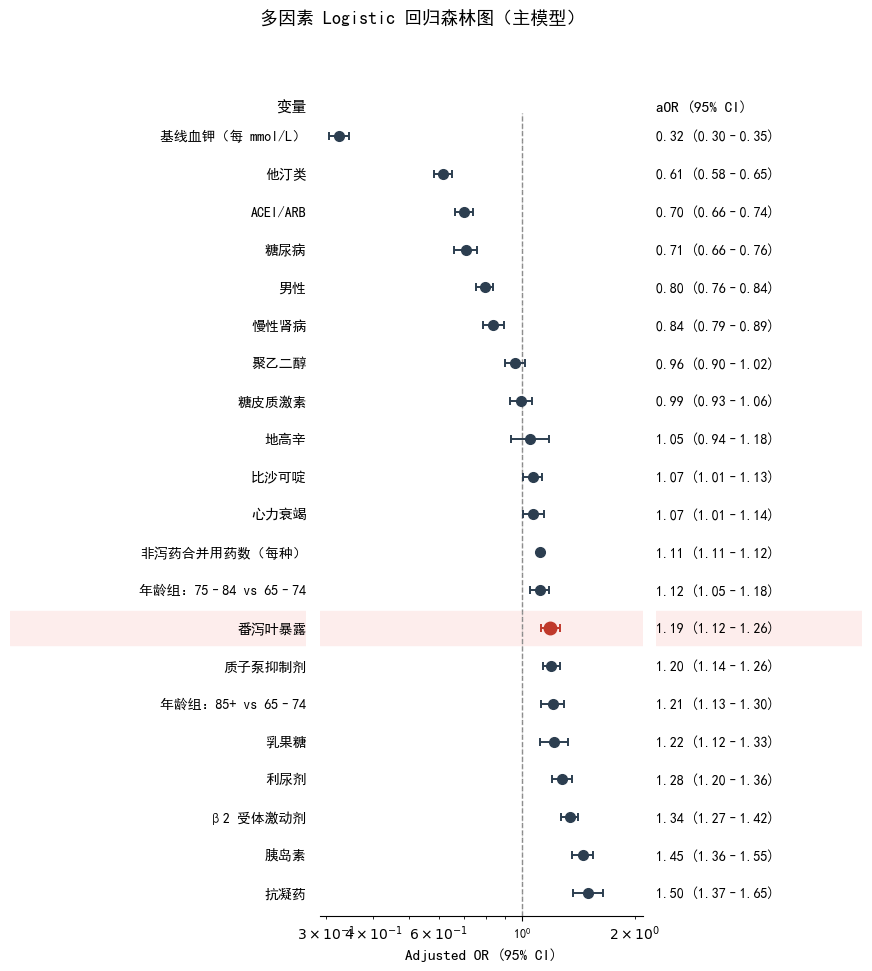

已保存: Figure_forest_multivariable_CN.png


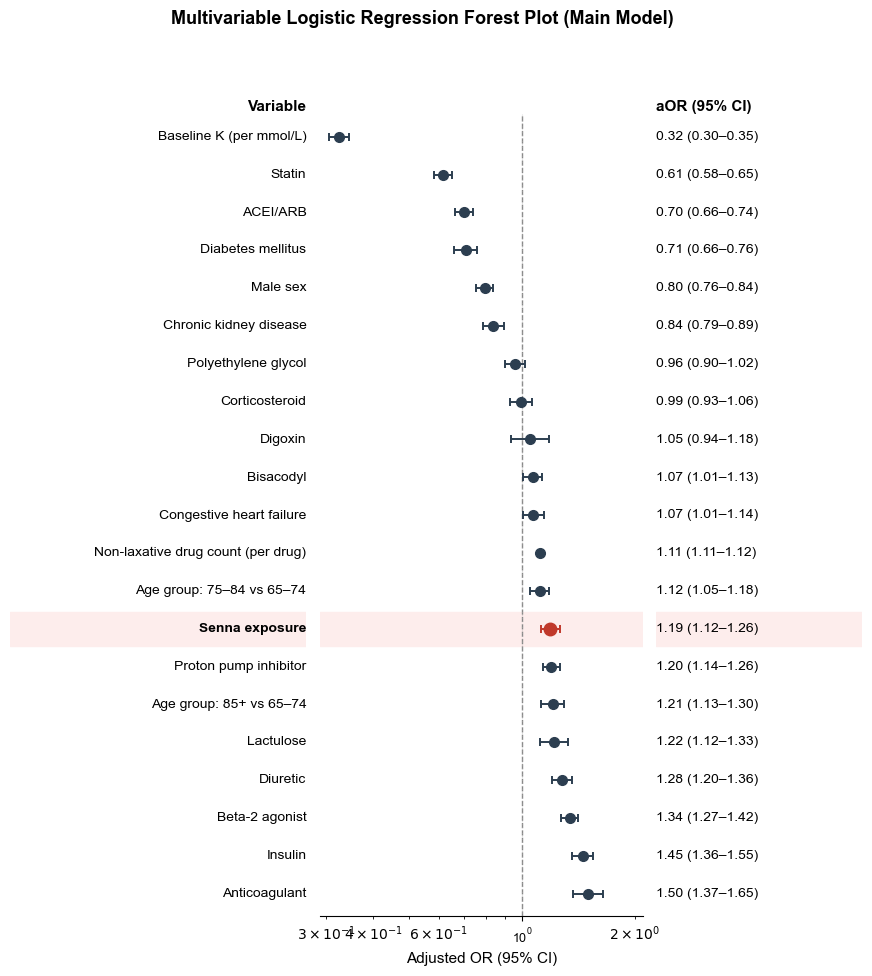

已保存: Figure_forest_multivariable_EN.png


In [27]:
# ========== 单元格 6：森林图（中英双版，无星号）==========
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

mpl.rcParams['axes.unicode_minus'] = False

# ---------- 变量标签 ----------
label_cn = {
    'senna_exposed': '番泻叶暴露',
    'gender_male': '男性',
    'baseline_k': '基线血钾（每 mmol/L）',
    'drug_count_no_laxatives': '非泻药合并用药数（每种）',
    'chf': '心力衰竭',
    'ckd': '慢性肾病',
    'dm': '糖尿病',
    'diuretic': '利尿剂',
    'acei_arb': 'ACEI/ARB',
    'digoxin': '地高辛',
    'insulin': '胰岛素',
    'statin': '他汀类',
    'anticoagulant': '抗凝药',
    'lactulose': '乳果糖',
    'peg': '聚乙二醇',
    'bisacodyl': '比沙可啶',
    'ppi': '质子泵抑制剂',
    'beta2_agonist': 'β2 受体激动剂',
    'corticosteroid': '糖皮质激素',
}
label_en = {
    'senna_exposed': 'Senna exposure',
    'gender_male': 'Male sex',
    'baseline_k': 'Baseline K (per mmol/L)',
    'drug_count_no_laxatives': 'Non-laxative drug count (per drug)',
    'chf': 'Congestive heart failure',
    'ckd': 'Chronic kidney disease',
    'dm': 'Diabetes mellitus',
    'diuretic': 'Diuretic',
    'acei_arb': 'ACEI/ARB',
    'digoxin': 'Digoxin',
    'insulin': 'Insulin',
    'statin': 'Statin',
    'anticoagulant': 'Anticoagulant',
    'lactulose': 'Lactulose',
    'peg': 'Polyethylene glycol',
    'bisacodyl': 'Bisacodyl',
    'ppi': 'Proton pump inhibitor',
    'beta2_agonist': 'Beta-2 agonist',
    'corticosteroid': 'Corticosteroid',
}
label_cn['age_85']   = '年龄组：85+ vs 65–74'
label_cn['age_7584'] = '年龄组：75–84 vs 65–74'
label_en['age_85']   = 'Age group: 85+ vs 65–74'
label_en['age_7584'] = 'Age group: 75–84 vs 65–74'

# ---------- 提取模型结果 ----------
def extract_plot_data(model, label_map):
    rows = []
    for term in model.params.index:
        if term == 'Intercept':
            continue
        if 'C(age_group' in term and '85+' in term:
            name = label_map['age_85']
        elif 'C(age_group' in term and '75-84' in term:
            name = label_map['age_7584']
        else:
            name = label_map.get(term, term)
        rows.append({
            'name': name,
            'OR': np.exp(model.params[term]),
            'lo': np.exp(model.conf_int().loc[term, 0]),
            'hi': np.exp(model.conf_int().loc[term, 1]),
            'p':  model.pvalues[term],
        })
    return pd.DataFrame(rows).sort_values('OR').reset_index(drop=True)

# ---------- 绘图函数 ----------
def plot_forest(pdf, title, save_path,
                highlight_var=None,
                font_family='Arial',
                col_label='Variable',
                col_or='aOR (95% CI)',
                fs_tick=10, fs_title=13, fs_axis=11, fs_text=10):

    n = len(pdf)
    fig = plt.figure(figsize=(11, 0.42 * n + 1.6))
    gs = fig.add_gridspec(1, 3, width_ratios=[2.3, 2.5, 1.6], wspace=0.05)
    ax_lab = fig.add_subplot(gs[0, 0])
    ax_f   = fig.add_subplot(gs[0, 1], sharey=ax_lab)
    ax_txt = fig.add_subplot(gs[0, 2], sharey=ax_lab)

    y = np.arange(n)[::-1]      # 从上到下排序
    log_lo = min(pdf['lo'].min(), 0.5)
    log_hi = max(pdf['hi'].max(), 2.0)
    xlim = (log_lo * 0.95, log_hi * 1.05)

    # ========== 左栏：变量名 ==========
    ax_lab.set_xlim(0, 1); ax_lab.set_ylim(-0.6, n - 0.4)
    ax_lab.axis('off')
    ax_lab.text(1.0, n - 0.4, col_label, ha='right', va='bottom',
                fontsize=fs_axis, fontweight='bold', family=font_family)
    for yi, name in zip(y, pdf['name']):
        is_hl = highlight_var and highlight_var in name
        ax_lab.text(1.0, yi, name, ha='right', va='center',
                    fontsize=fs_tick, family=font_family,
                    fontweight='bold' if is_hl else 'normal')

    # ========== 中栏：森林图 ==========
    ax_f.set_xscale('log')
    ax_f.set_xlim(xlim)
    ax_f.set_ylim(-0.6, n - 0.4)
    ax_f.axvline(1, color='#888888', linestyle='--', linewidth=1, zorder=1)

    # 高亮行背景
    for yi, name in zip(y, pdf['name']):
        if highlight_var and highlight_var in name:
            for ax in (ax_lab, ax_f, ax_txt):
                ax.axhspan(yi - 0.45, yi + 0.45,
                           color='#FDEDEC', zorder=0)

    for yi, (_, row) in zip(y, pdf.iterrows()):
        is_hl = highlight_var and highlight_var in row['name']
        c  = '#C0392B' if is_hl else '#2C3E50'
        ms = 9 if is_hl else 7
        ax_f.errorbar(row['OR'], yi,
                      xerr=[[row['OR'] - row['lo']], [row['hi'] - row['OR']]],
                      fmt='o', color=c, ecolor=c,
                      elinewidth=1.4, capsize=3, capthick=1.4,
                      markersize=ms, zorder=3)

    ax_f.set_yticks([])
    ax_f.set_xlabel('Adjusted OR (95% CI)', fontsize=fs_axis, family=font_family)
    ax_f.tick_params(axis='x', labelsize=fs_tick - 1)
    for tick in ax_f.get_xticklabels():
        tick.set_family(font_family)
    ax_f.spines['top'].set_visible(False)
    ax_f.spines['right'].set_visible(False)
    ax_f.spines['left'].set_visible(False)
    ax_f.grid(axis='x', linestyle=':', alpha=0.4, zorder=0)

    # ========== 右栏：数值（无星号）==========
    ax_txt.set_xlim(0, 1); ax_txt.set_ylim(-0.6, n - 0.4)
    ax_txt.axis('off')
    ax_txt.text(0.0, n - 0.4, col_or, ha='left', va='bottom',
                fontsize=fs_axis, fontweight='bold', family=font_family)
    for yi, (_, row) in zip(y, pdf.iterrows()):
        txt = f"{row['OR']:.2f} ({row['lo']:.2f}–{row['hi']:.2f})"
        ax_txt.text(0.0, yi, txt, ha='left', va='center',
                    fontsize=fs_text, family=font_family)

    fig.suptitle(title, fontsize=fs_title, fontweight='bold',
                 family=font_family, y=0.98)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()
    print(f'已保存: {save_path}')

# ---------- 生成中英两版 ----------
pdf_cn = extract_plot_data(model_main, label_cn)
pdf_en = extract_plot_data(model_main, label_en)

# 中文版
plot_forest(pdf_cn,
            title='多因素 Logistic 回归森林图（主模型）',
            save_path='Figure_forest_multivariable_CN.png',
            highlight_var='番泻叶',
            font_family='SimHei',
            col_label='变量',
            col_or='aOR (95% CI)')

# 英文版（Arial）
plot_forest(pdf_en,
            title='Multivariable Logistic Regression Forest Plot (Main Model)',
            save_path='Figure_forest_multivariable_EN.png',
            highlight_var='Senna',
            font_family='Arial',
            col_label='Variable',
            col_or='aOR (95% CI)')